# Base 2: exploração, ACF, STL e tratamento

Este notebook transforma apenas a entrada estrutural da Base 2 em um CSV `cleaned`, sem alterar os arquivos congelados. A ACF e a STL usam o maior segmento regular e completo do alvo, sem preencher ausências somente para gerar gráfico.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "configs").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from discovery_series_temporais.cleaning import build_cleaned_dataset, plot_cleaned_diagnostics

BASE_ID = 2
cleaned, summary = build_cleaned_dataset(BASE_ID, ROOT / "data" / "processed")
display(pd.DataFrame([{
    "base": summary.base_id,
    "target_original": summary.target_name,
    "rows": summary.rows,
    "columns": summary.columns,
    "missing_target": summary.missing_target,
    "cleaned_output": str(summary.output_path),
    "actions": "; ".join(summary.actions),
}]))
display(cleaned.head())
display(cleaned.isna().sum().rename("missing_values").to_frame())


,base,target_original,rows,columns,missing_target,cleaned_output,actions
0,2,traffic_volume,40575,9,0,C:\Users\mayumishimizu-ieg\.codex\.chatgpt-pro...,verified that repeated traffic_volume values a...


,timestamp,target,temp,rain_1h,snow_1h,clouds_all,holiday,weather_main,weather_description
0,2012-10-02 09:00:00,5545,288.28,0.0,0.0,40.0,No holiday,Clouds,scattered clouds
1,2012-10-02 10:00:00,4516,289.36,0.0,0.0,75.0,No holiday,Clouds,broken clouds
2,2012-10-02 11:00:00,4767,289.58,0.0,0.0,90.0,No holiday,Clouds,overcast clouds
3,2012-10-02 12:00:00,5026,290.13,0.0,0.0,90.0,No holiday,Clouds,overcast clouds
4,2012-10-02 13:00:00,4918,291.14,0.0,0.0,75.0,No holiday,Clouds,broken clouds


,missing_values
timestamp,0
target,0
temp,0
rain_1h,0
snow_1h,0
clouds_all,0
holiday,0
weather_main,0
weather_description,0


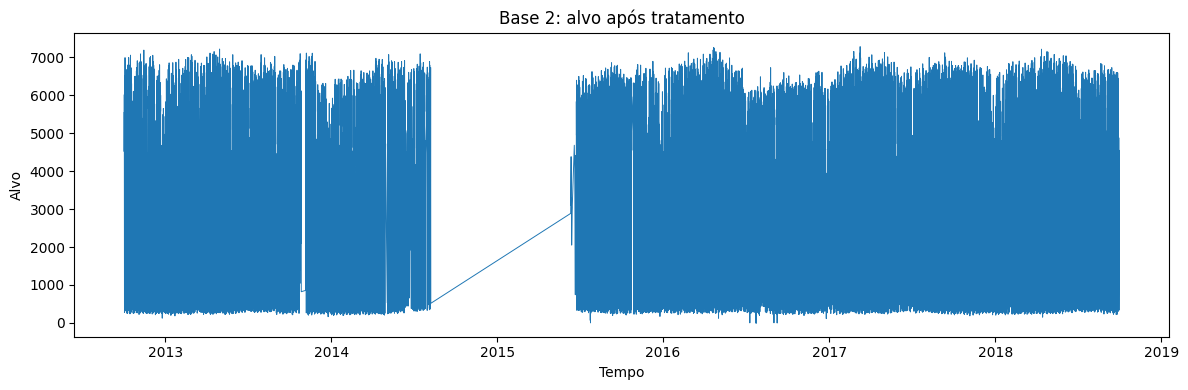

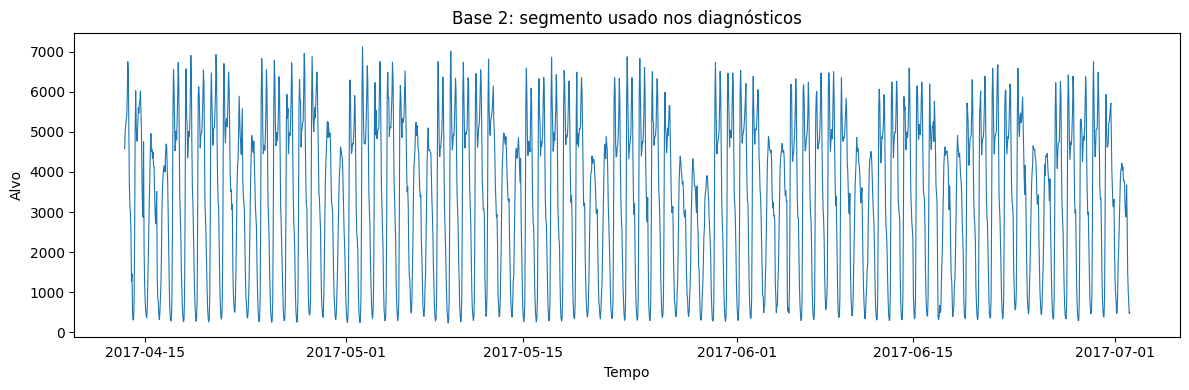

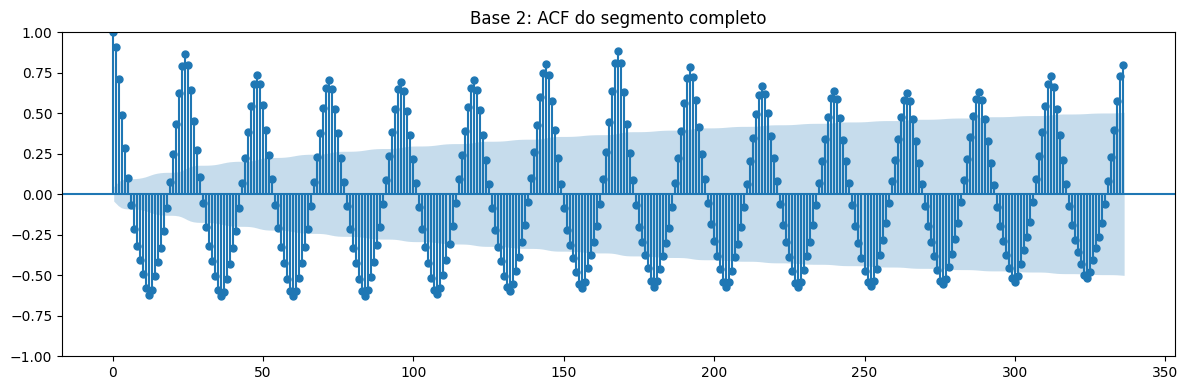

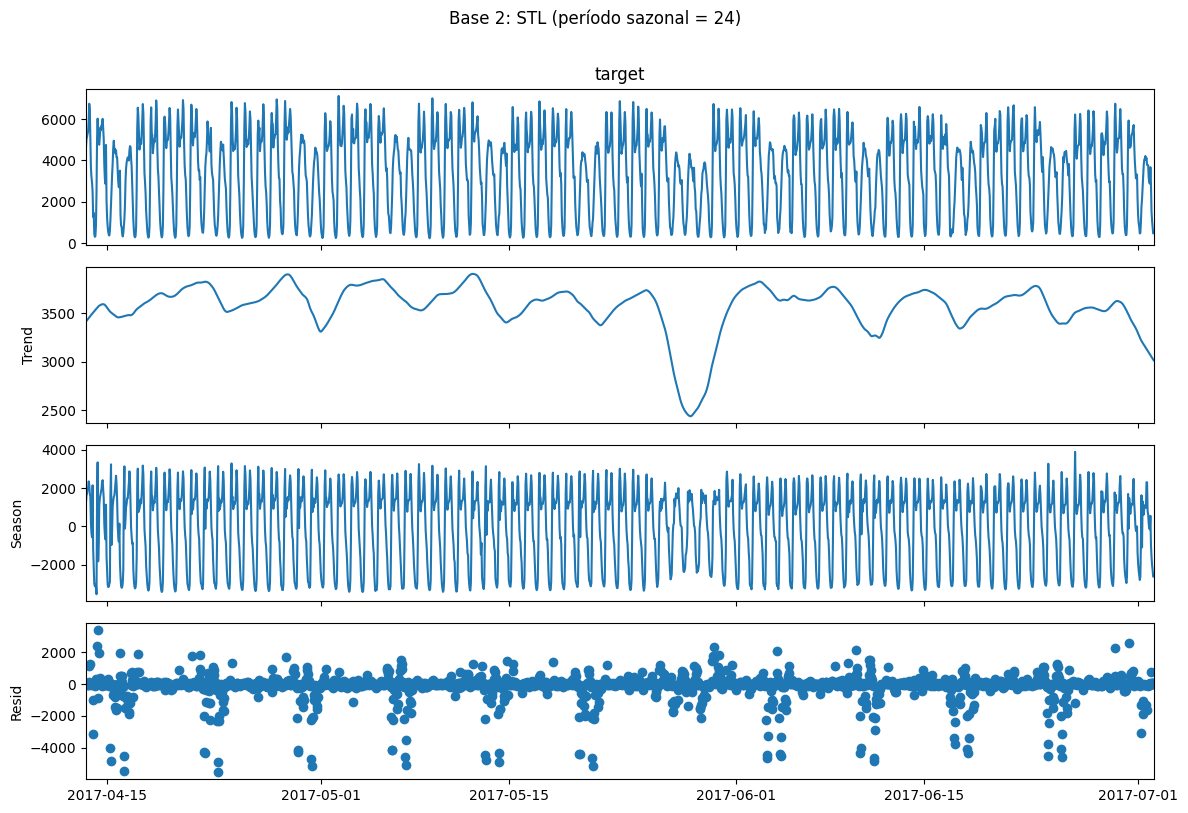

,segment_start,segment_end,segment_points,stl_seasonal_period,acf_lags
0,2017-04-13 10:00:00,2017-07-02 04:00:00,1915,24,336


In [2]:
figure, axis = plt.subplots(figsize=(12, 4))
axis.plot(cleaned["timestamp"], cleaned["target"], linewidth=0.7)
axis.set(title=f"Base {BASE_ID}: alvo após tratamento", xlabel="Tempo", ylabel="Alvo")
figure.tight_layout()
plt.show()

diagnostic = plot_cleaned_diagnostics(
    cleaned,
    BASE_ID,
    ROOT / "reports" / "generated" / "exploration" / f"base{BASE_ID}",
)
display(pd.DataFrame([{
    "segment_start": diagnostic.data["timestamp"].min(),
    "segment_end": diagnostic.data["timestamp"].max(),
    "segment_points": len(diagnostic.data),
    "stl_seasonal_period": diagnostic.seasonal_period,
    "acf_lags": diagnostic.acf_lags,
}]))
